In [1]:
!pip -q install torch torchvision pillow

import io
import json
import time
import uuid
import base64

import torch
import torchvision
import torch.nn.functional as F
import torchvision.transforms.functional as TF

from PIL import Image, ImageOps, UnidentifiedImageError
from torchvision.models import resnet18, ResNet18_Weights

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

weights = ResNet18_Weights.DEFAULT
model = resnet18(weights=weights).to(device)
model.eval()

# ResNet18 ImageNet normalization
MEAN = weights.transforms().mean
STD = weights.transforms().std

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Device:", device)
print("Classes:", len(weights.meta["categories"]))


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 138MB/s]


PyTorch: 2.14.1+cpu
Torchvision: 0.29.1+cpu
Device: cpu
Classes: 1000


In [2]:
MAX_BYTES = 10 * 1024 * 1024  # 10 MB
ALLOWED_FORMATS = {"JPEG", "PNG"}
TARGET_SIZE = 224

def validate_and_decode(image_bytes):
    if not isinstance(image_bytes, bytes) or not image_bytes:
        raise ValueError("Empty or invalid image payload")

    if len(image_bytes) > MAX_BYTES:
        raise ValueError("Image exceeds the 10 MB limit")

    # Verify that the payload is a valid supported image.
    with Image.open(io.BytesIO(image_bytes)) as img:
        if img.format not in ALLOWED_FORMATS:
            raise ValueError("Only JPEG and PNG are supported")
        img.verify()

    # Reopen after verify; verify() invalidates normal image use.
    with Image.open(io.BytesIO(image_bytes)) as img:
        img = ImageOps.exif_transpose(img).convert("RGB")
        original_size = img.size
        img.load()

    return img, original_size

print("Validation and decoding functions ready.")


Validation and decoding functions ready.


In [5]:
def letterbox(image, size=224):
    original_w, original_h = image.size

    scale = min(size / original_w, size / original_h)
    new_w = max(1, round(original_w * scale))
    new_h = max(1, round(original_h * scale))

    resized = image.resize(
        (new_w, new_h), Image.Resampling.BILINEAR
    )

    canvas = Image.new("RGB", (size, size), (114, 114, 114))

    left = (size - new_w) // 2
    top = (size - new_h) // 2

    canvas.paste(resized, (left, top))

    info = {
        "original_size": [original_w, original_h],
        "resized_size": [new_w, new_h],
        "letterbox_size": [size, size],
        "padding": {
            "left": left,
            "top": top,
            "right": size - new_w - left,
            "bottom": size - new_h - top
        }
    }

    return canvas, info

print("Letterboxing function ready.")


Letterboxing function ready.


In [6]:

def run_inference_request(image_bytes):
    request_id = str(uuid.uuid4())
    trace = {}
    total_start = time.perf_counter()

    try:
        # 1. Validate and decode
        start = time.perf_counter()
        image, original_size = validate_and_decode(image_bytes)
        trace["validation_decode_ms"] = round(
            (time.perf_counter() - start) * 1000, 3
        )

        # 2. Resize and letterbox
        start = time.perf_counter()
        processed, resize_info = letterbox(image, TARGET_SIZE)
        trace["resize_letterbox_ms"] = round(
            (time.perf_counter() - start) * 1000, 3
        )

        # 3. Convert HWC uint8 image to normalized NCHW float32 tensor
        start = time.perf_counter()
        tensor = TF.to_tensor(processed)
        tensor = TF.normalize(tensor, mean=MEAN, std=STD)
        tensor = tensor.unsqueeze(0).contiguous()

        trace["tensor_prepare_ms"] = round(
            (time.perf_counter() - start) * 1000, 3
        )
        input_shape = list(tensor.shape)
        input_dtype = str(tensor.dtype)

        # 4. Transfer tensor to selected device
        if device.type == "cuda":
            torch.cuda.synchronize()

        start = time.perf_counter()
        tensor = tensor.to(device)

        if device.type == "cuda":
            torch.cuda.synchronize()

        trace["device_transfer_ms"] = round(
            (time.perf_counter() - start) * 1000, 3
        )

        # 5. Model invocation
        start = time.perf_counter()

        with torch.inference_mode():
            logits = model(tensor)

        if device.type == "cuda":
            torch.cuda.synchronize()

        trace["model_inference_ms"] = round(
            (time.perf_counter() - start) * 1000, 3
        )
        logits_shape = list(logits.shape)

        # 6. Postprocessing
        start = time.perf_counter()

        probabilities = F.softmax(logits, dim=1)
        confidence, index = probabilities.max(dim=1)

        predicted_index = index.item()
        predicted_class = weights.meta["categories"][predicted_index]
        confidence_value = float(confidence.item())

        trace["postprocessing_ms"] = round(
            (time.perf_counter() - start) * 1000, 3
        )

        # 7. Construct and serialize response
        response = {
            "request_id": request_id,
            "status": "success",
            "input": {
                "format": "JPEG or PNG",
                "original_size_wh": list(original_size),
                "decoded_format": "RGB"
            },
            "preprocessing": resize_info,
            "tensor": {
                "shape": input_shape,
                "dtype": input_dtype,
                "device": str(device)
            },
            "model_output": {
                "shape": logits_shape,
                "class_count": len(weights.meta["categories"])
            },
            "prediction": {
                "class_index": predicted_index,
                "class_name": predicted_class,
                "confidence": round(confidence_value, 6)
            },
            "timings_ms": trace
        }

        response["timings_ms"]["total_ms"] = round(
            (time.perf_counter() - total_start) * 1000, 3
        )

        start = time.perf_counter()
        response_json = json.dumps(response, indent=2)
        serialization_ms = round(
            (time.perf_counter() - start) * 1000, 3
        )

        # Serialization time is measured after the response was constructed.
        response["timings_ms"]["serialization_ms"] = serialization_ms
        response_json = json.dumps(response, indent=2)

        return response_json

    except (ValueError, UnidentifiedImageError, OSError) as exc:
        error = {
            "request_id": request_id,
            "status": "error",
            "error_type": type(exc).__name__,
            "message": str(exc),
            "timings_ms": {
                "total_ms": round(
                    (time.perf_counter() - total_start) * 1000, 3
                )
            }
        }
        return json.dumps(error, indent=2)

print("Inference request pipeline ready.")


Inference request pipeline ready.


In [7]:
from google.colab import files

uploaded = files.upload()

filename = next(iter(uploaded))
image_bytes = uploaded[filename]

response_json = run_inference_request(image_bytes)
result = json.loads(response_json)

print("Filename:", filename)
print(json.dumps(result, indent=2))


Saving trfiicc.jpg to trfiicc.jpg
Filename: trfiicc.jpg
{
  "request_id": "bc03d8ac-bdca-4181-94d0-e3998eed7643",
  "status": "success",
  "input": {
    "format": "JPEG or PNG",
    "original_size_wh": [
      3456,
      4258
    ],
    "decoded_format": "RGB"
  },
  "preprocessing": {
    "original_size": [
      3456,
      4258
    ],
    "resized_size": [
      182,
      224
    ],
    "letterbox_size": [
      224,
      224
    ],
    "padding": {
      "left": 21,
      "top": 0,
      "right": 21,
      "bottom": 0
    }
  },
  "tensor": {
    "shape": [
      1,
      3,
      224,
      224
    ],
    "dtype": "torch.float32",
    "device": "cpu"
  },
  "model_output": {
    "shape": [
      1,
      1000
    ],
    "class_count": 1000
  },
  "prediction": {
    "class_index": 468,
    "class_name": "cab",
    "confidence": 0.860941
  },
  "timings_ms": {
    "validation_decode_ms": 373.212,
    "resize_letterbox_ms": 107.957,
    "tensor_prepare_ms": 82.302,
    "device_t

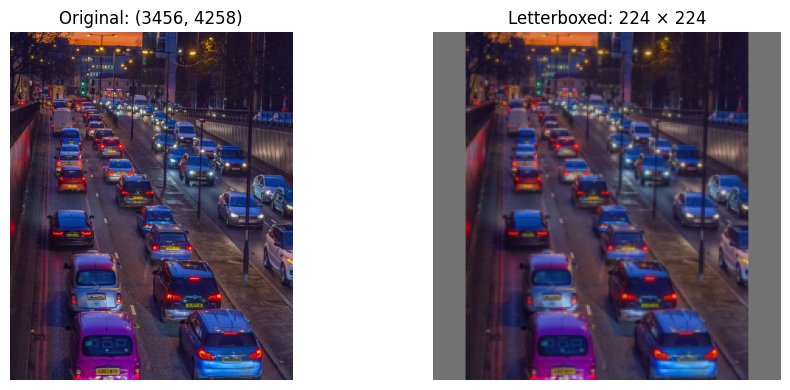

Original image size (W, H): (3456, 4258)
Resized dimensions: [182, 224]
Padding: {'left': 21, 'top': 0, 'right': 21, 'bottom': 0}
Tensor shape: (1, 3, 224, 224)
Tensor dtype: torch.float32
Tensor device before transfer: cpu
Tensor value range: -2.084 to 2.57


In [8]:
import matplotlib.pyplot as plt

image, original_size = validate_and_decode(image_bytes)
processed, resize_info = letterbox(image)

tensor = TF.normalize(
    TF.to_tensor(processed), mean=MEAN, std=STD
).unsqueeze(0)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(image)
axes[0].set_title(f"Original: {original_size}")
axes[0].axis("off")

axes[1].imshow(processed)
axes[1].set_title("Letterboxed: 224 × 224")
axes[1].axis("off")

plt.tight_layout()
plt.show()

print("Original image size (W, H):", original_size)
print("Resized dimensions:", resize_info["resized_size"])
print("Padding:", resize_info["padding"])
print("Tensor shape:", tuple(tensor.shape))
print("Tensor dtype:", tensor.dtype)
print("Tensor device before transfer:", tensor.device)
print("Tensor value range:",
      round(tensor.min().item(), 3),
      "to",
      round(tensor.max().item(), 3))


In [9]:
test_cases = [
    ("Empty payload", b""),
    ("Invalid image bytes", b"this is not an image"),
    ("Unsupported format", b""),
]

for name, payload in test_cases:
    print("\nTest:", name)
    print(run_inference_request(payload))


Test: Empty payload
{
  "request_id": "a5235d1f-d08d-4c57-9cbd-93ef090d2003",
  "status": "error",
  "error_type": "ValueError",
  "message": "Empty or invalid image payload",
  "timings_ms": {
    "total_ms": 0.01
  }
}

Test: Invalid image bytes
{
  "request_id": "ec4b7c07-4156-415d-b681-966fbb7ac0c5",
  "status": "error",
  "error_type": "UnidentifiedImageError",
  "message": "cannot identify image file <_io.BytesIO object at 0x7a78c45e71f0>",
  "timings_ms": {
    "total_ms": 277.049
  }
}

Test: Unsupported format
{
  "request_id": "46f961ed-bb6e-4d8a-9c9f-be8613e02ef3",
  "status": "error",
  "error_type": "ValueError",
  "message": "Empty or invalid image payload",
  "timings_ms": {
    "total_ms": 0.008
  }
}
